# Cartes

Les cartes montrent où se trouvent les départements les plus touchés par l'obésité, et si on retrouve les mêmes zones pour la pauvreté, les fast-foods et l'accès aux médecins.

## 1. Chargement

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

contours = gpd.read_file("../data/raw/departements.geojson")
df = pd.read_csv("../data/processed/departements.csv", dtype={"dep": str, "region": str})

carte = contours.merge(df, left_on="code", right_on="dep")
carte = carte.to_crs(2154)
carte.shape

(96, 20)

On relie les contours des départements à la table par leur code. `to_crs(2154)` change la projection en Lambert-93, la projection officielle de la France : sans ça, la carte paraît étirée.

## 2. Obésité

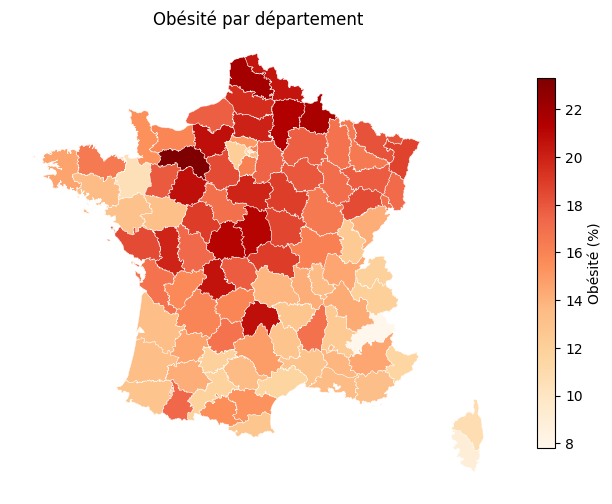

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
carte.plot(
    column="obesite",
    cmap="OrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    ax=ax,
    legend_kwds={"label": "Obésité (%)", "shrink": 0.6},
)
ax.set_axis_off()
ax.set_title("Obésité par département")
plt.savefig("../figures/carte_obesite.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :** les taux les plus élevés sont dans le nord (Hauts-de-France), en Normandie et dans un large centre du pays. Les taux les plus faibles sont dans le sud-est et les Alpes, en Corse, à Paris et en Ille-et-Vilaine. On voit un contraste entre le nord et le centre d'un côté, et le sud de l'autre. Les départements voisins ont des taux proches : la région compte beaucoup, ce que la régression a confirmé.

## 3. Pauvreté

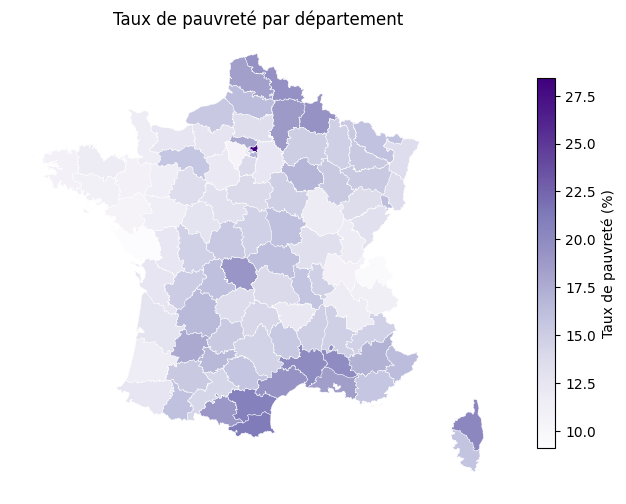

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
carte.plot(
    column="taux_pauvrete",
    cmap="Purples",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    ax=ax,
    legend_kwds={"label": "Taux de pauvreté (%)", "shrink": 0.6},
)
ax.set_axis_off()
ax.set_title("Taux de pauvreté par département")
plt.savefig("../figures/carte_pauvrete.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :** la pauvreté est la plus forte en Seine-Saint-Denis (28,4 %, le petit département foncé à côté de Paris), dans le nord (Nord, Pas-de-Calais, Aisne, Ardennes) et sur le pourtour méditerranéen (Pyrénées-Orientales, Aude, Gard, Vaucluse, Haute-Corse). Elle est faible dans l'ouest et dans les Alpes.

**Comparaison avec l'obésité :** le nord est élevé sur les deux cartes. Mais le sud méditerranéen est pauvre et peu touché par l'obésité, alors que l'ouest est peu pauvre et assez touché. Les deux cartes ne se superposent donc pas, ce qui explique la corrélation quasi nulle entre pauvreté et obésité, et pourquoi il a fallu tenir compte de la région dans la régression.

## 4. Fast-foods

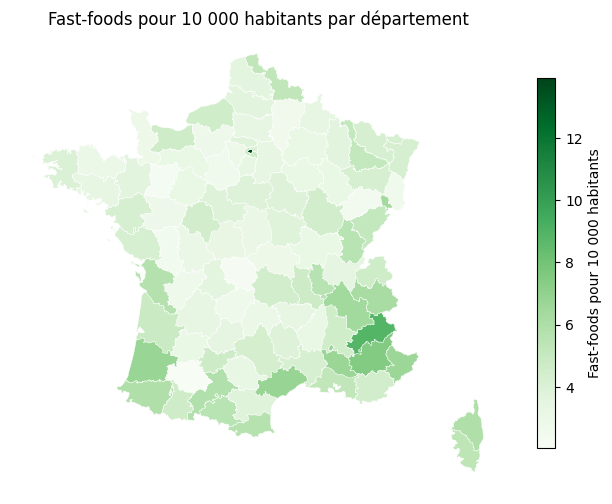

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
carte.plot(
    column="fastfoods_10k",
    cmap="Greens",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    ax=ax,
    legend_kwds={"label": "Fast-foods pour 10 000 habitants", "shrink": 0.6},
)
ax.set_axis_off()
ax.set_title("Fast-foods pour 10 000 habitants par département")
plt.savefig("../figures/carte_fastfoods.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :** les fast-foods sont les plus nombreux à Paris (13,9 pour 10 000 habitants, le petit département foncé), dans les Alpes du Sud (Hautes-Alpes 8,9, Alpes-de-Haute-Provence 7,5) et le long de la côte méditerranéenne et atlantique. Ils sont peu nombreux dans le centre du pays.

**Comparaison avec l'obésité :** les zones riches en fast-foods (Paris, sud-est) sont des zones où l'obésité est plutôt faible. C'est ce que montraient la corrélation négative et la régression : le nombre de fast-foods reflète surtout le profil du territoire (grandes villes, tourisme), pas un effet protecteur.

## 5. Accès aux médecins

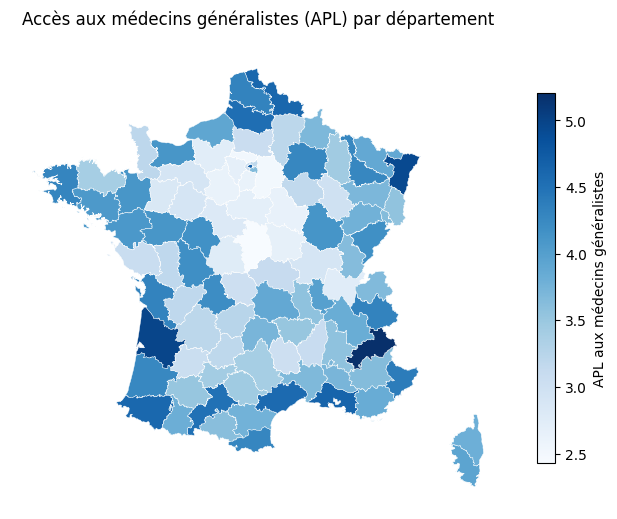

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
carte.plot(
    column="apl",
    cmap="Blues",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    ax=ax,
    legend_kwds={"label": "APL aux médecins généralistes", "shrink": 0.6},
)
ax.set_axis_off()
ax.set_title("Accès aux médecins généralistes (APL) par département")
plt.savefig("../figures/carte_apl.png", dpi=150, bbox_inches="tight")
plt.show()

Plus l'APL est élevée, meilleur est l'accès aux médecins généralistes.

**Interprétation :** l'accès est le meilleur dans les Hautes-Alpes (5,2), la Gironde, le Bas-Rhin, Paris, les Bouches-du-Rhône et le Nord, c'est-à-dire autour de grandes villes ou sur des zones touristiques. Il est le plus faible dans une bande qui traverse le centre du pays (Cher, Eure-et-Loir, Yonne) et autour de Paris (Seine-et-Marne, Val-d'Oise, Essonne).

**Comparaison avec l'obésité :** le centre du pays a à la fois un accès faible aux médecins et une obésité élevée, alors que le sud-est cumule bon accès et obésité faible. Le recoupement est partiel, ce qui correspond à la corrélation modérée vue dans le descriptif (-0,35).

## 6. Ce qu'on retient des cartes

- L'obésité forme de grands ensembles géographiques : élevée dans le nord, en Normandie et au centre, faible dans le sud-est, en Corse, à Paris et en Ille-et-Vilaine. Les départements voisins se ressemblent.
- La carte de la pauvreté ne se superpose pas à celle de l'obésité : le nord est élevé sur les deux, mais le sud méditerranéen est pauvre et peu touché, alors que l'ouest est peu pauvre et assez touché.
- Les fast-foods sont nombreux dans les zones où l'obésité est faible (Paris, sud-est), ce qui reflète le profil des territoires (villes, tourisme) plus qu'un effet protecteur.
- Le centre du pays cumule un accès faible aux médecins et une obésité élevée.
- Les cartes décrivent des ressemblances entre zones, elles ne prouvent aucun lien. C'est la régression qui teste ce qui reste une fois la région prise en compte.